# Medical Insurance Cost Prediction System
## Exploratory Data Analysis (EDA)

---

## 1. Project Introduction

### Objective
The goal of this project is to develop a supervised machine learning system that predicts the yearly medical insurance charges of a person.

This is a **Regression** problem because the target variable (`charges`) is a continuous numerical value.

### Why this matters
- Insurance companies can set fair premiums for each customer.
- Individuals can estimate their expected medical costs.
- Healthcare planners can identify the groups with the highest costs.

### Dataset
Medical Cost Personal Dataset (Kaggle): 1338 records, 7 columns.

- **Target:** `charges`
- **Features:** `age`, `sex`, `bmi`, `children`, `smoker`, `region`

### Project Workflow
1. Data Loading and Understanding
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing
4. Model Building
5. Model Evaluation
6. Model Saving
7. Streamlit Application Development
8. Testing and Deployment

----
## 2. Environment Setup and Data Loading

### Objective
Prepare the notebook environment and load the dataset from the project's raw data directory.

### Steps
- Add the project root to the Python path to access reusable modules in `src/`.
- Import the required libraries.
- Load the raw dataset using `load_raw_data()` from `src.data_loader`.

----
## 2. Environment Setup and Data Loading

### Objective
Prepare the notebook environment and load the dataset from the project's raw data directory.

### Steps
- Add the project root to the Python path to access reusable modules in `src/`.
- Import the required libraries.
- Load the raw dataset using `load_raw_data()` from `src.data_loader`.

In [28]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_loader import load_raw_data

In [29]:
df = load_raw_data()
df.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


### Result
The dataset was successfully loaded from `data/raw/insurance.csv`.

The raw file is kept untouched. Any cleaning is done later in code on a copy, so the original data is always preserved.

----
## 3. Initial Dataset Inspection

### Objective
Understand the general structure of the dataset and check its quality.

### Steps
- Number of rows and columns, and column data types.
- Missing values.
- Duplicate records.

In [30]:
df.shape

(1338, 7)

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [32]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [33]:
df.duplicated().sum()

np.int64(1)

In [34]:
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


In [35]:
from src.preprocessing import clean_data

df= clean_data(df)
print(df.shape)

(1337, 7)


### Key Findings
- Total records: **1338**
- Total columns: **7**
- Missing values: **0** in every column
- Duplicate rows: **1** (row 581 is identical to row 195 in all 7 columns)
- `sex`, `smoker` and `region` are text columns; `age` and `children` are integers; `bmi` and `charges` are floats.

### Decision
- No imputation is needed because there are no missing values.
- The duplicated row is almost certainly a data entry duplicate (even `charges` matches to 4 decimals), so it is removed in preprocessing using `clean_data()` from `src/preprocessing.py`. The raw file stays unchanged.

----
## 4. Understanding Features and Target Variable

### Objective
Identify the role of each column and understand the distribution of the target variable.

### Column roles
| Column | Type | Role |
|---|---|---|
| `age` | numerical | feature |
| `sex` | categorical | feature |
| `bmi` | numerical | feature |
| `children` | numerical | feature |
| `smoker` | categorical | feature |
| `region` | categorical | feature |
| `charges` | numerical | **target** |

### Steps
Plot the distribution of `charges`.

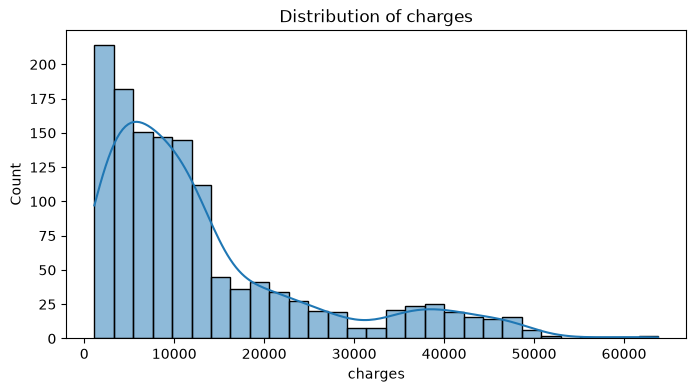

In [36]:
plt.figure(figsize=(8, 4))
sns.histplot(df["charges"], kde=True)
plt.title("Distribution of charges")
plt.show()

### Key Findings
- The distribution is **right-skewed**: the mean (13,270) is higher than the median (9,382).
- Most people have low charges, while a few have very high charges (max 63,770).
- A small second bump appears around 35,000-50,000, which suggests two different groups (investigated in the next sections).

### Decision
Apply a log transform to `charges` in preprocessing to reduce the skewness.

----
## 5. Numerical Features Analysis

### Objective
Understand the statistical characteristics of the numerical features and look for unusual values.

### Steps
- Descriptive statistics with `describe()`.
- Boxplots and histograms to detect outliers.
- Count the outliers with the IQR rule.

In [37]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


### Key Findings (statistics)
| Feature | Min | Mean | Max |
|---|---:|---:|---:|
| `age` | 18 | 39.2 | 64 |
| `bmi` | 15.96 | 30.66 | 53.13 |
| `children` | 0 | 1.09 | 5 |
| `charges` | 1,121.87 | 13,270.42 | 63,770.43 |

- No impossible values (no negative age, BMI or charges).
- The average BMI (30.66) is already in the obesity range (30+).
- `charges` has a large gap between mean and median, and its max is far above the 75th percentile (16,640), which points to high-value outliers.

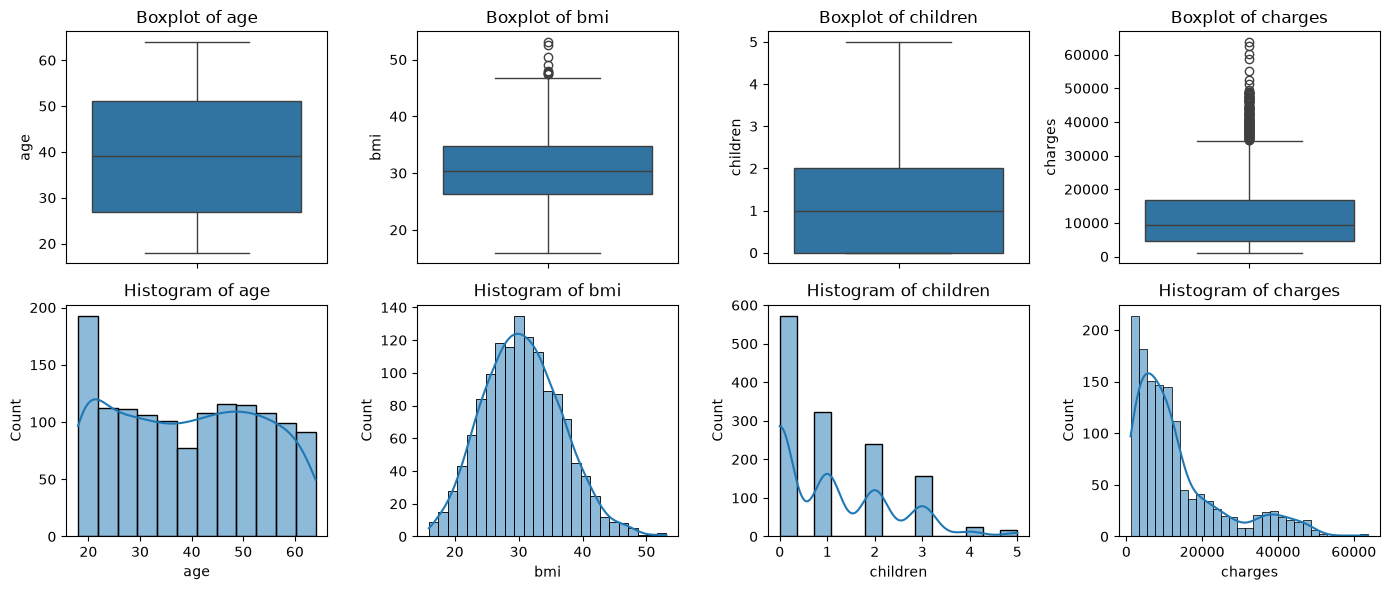

In [38]:
numerical_features = ["age", "bmi", "children", "charges"]

plt.figure(figsize=(14, 6))

for i, col in enumerate(numerical_features):
    plt.subplot(2, 4, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")

for i, col in enumerate(numerical_features):
    plt.subplot(2, 4, i + 5)
    sns.histplot(df[col], kde=True)
    plt.title(f"Histogram of {col}")

plt.tight_layout()
plt.show()

In [39]:
for col in ["bmi", "charges"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col}: {n} outliers (outside {lower:.2f} to {upper:.2f})")

bmi: 9 outliers (outside 13.67 to 47.32)
charges: 139 outliers (outside -13120.72 to 34524.78)


### Outliers Findings
- `bmi` has **__** outliers and `charges` has **__** outliers (IQR rule). *(fill in the numbers from the cell above)*
- The `charges` outliers are all on the high side. They are real high-cost cases, not data errors.
- `age` and `children` have no outliers.

### Decision
Outliers are **kept**. They are valid observations and removing them would delete the expensive cases the model needs to learn. The log transform on `charges` reduces their influence.

----
## 6. Data Validation

### Objective
Check that the values make sense (no negative or impossible values).

### Steps
Count zero and negative values in the numerical columns.

In [40]:
for col in ["age", "bmi", "children", "charges"]:
    print(f"{col} | zeros: {(df[col] == 0).sum()} | negatives: {(df[col] < 0).sum()}")

age | zeros: 0 | negatives: 0
bmi | zeros: 0 | negatives: 0
children | zeros: 573 | negatives: 0
charges | zeros: 0 | negatives: 0


In [41]:
df["children"].value_counts().sort_index()

children
0    573
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64

### Key Findings
- No negative values in any column.
- The only zeros are in `children`, which is valid (a person can have no children).
- `age` ranges from 18 to 64 and `bmi` from 15.96 to 53.13, both realistic.

### Decision
No value is changed or removed. All values are valid.

----
## 7. Categorical Features Analysis

### Objective
Check the distribution of the categorical features and whether the categories are balanced.

### Steps
Count the categories of `sex`, `smoker` and `region`.

In [42]:
for col in ["sex", "smoker", "region"]:
    print(col)
    print(df[col].value_counts())
    print((df[col].value_counts(normalize=True) * 100).round(2))
    print("-" * 40)

sex
sex
male      675
female    662
Name: count, dtype: int64
sex
male      50.49
female    49.51
Name: proportion, dtype: float64
----------------------------------------
smoker
smoker
no     1063
yes     274
Name: count, dtype: int64
smoker
no     79.51
yes    20.49
Name: proportion, dtype: float64
----------------------------------------
region
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64
region
southeast    27.23
southwest    24.31
northwest    24.23
northeast    24.23
Name: proportion, dtype: float64
----------------------------------------


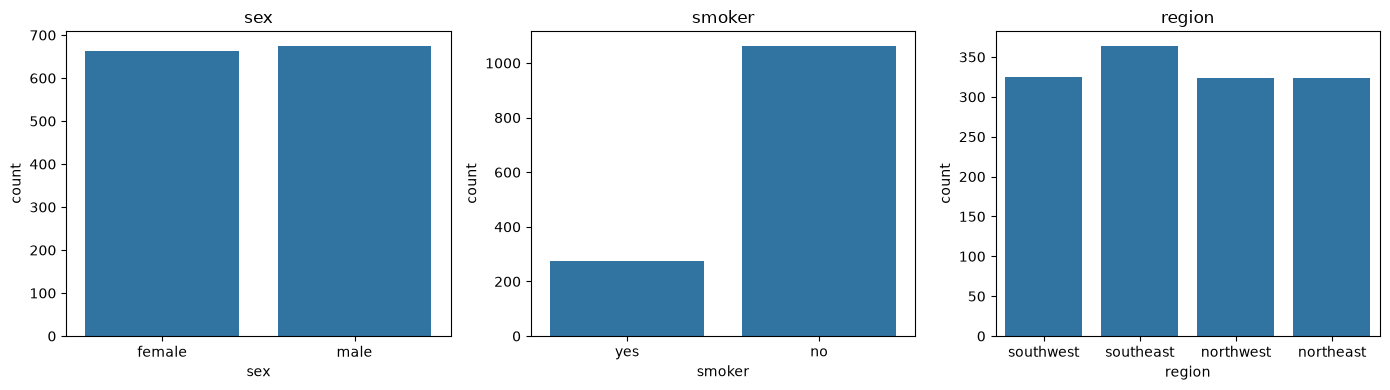

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["sex", "smoker", "region"]):
    sns.countplot(x=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

### Key Findings
- `smoker`: about 20% smokers (274 of 1338), so this feature is imbalanced.
- `sex` and `region` have roughly balanced categories.
- No unexpected category or spelling variation.

### Decision
No category is rare, so none will be merged. All three columns will be encoded to numbers in preprocessing.

----
## 8. Date Feature Analysis
The dataset has no date column, so this step is not needed.

----
## 9. Numerical Features vs. Target Analysis

### Objective
Explore the relationship between each numerical feature and `charges`.

### Steps
- Scatter plots for `age` vs `charges` and `bmi` vs `charges`.
- Group by `children` and compare charges.

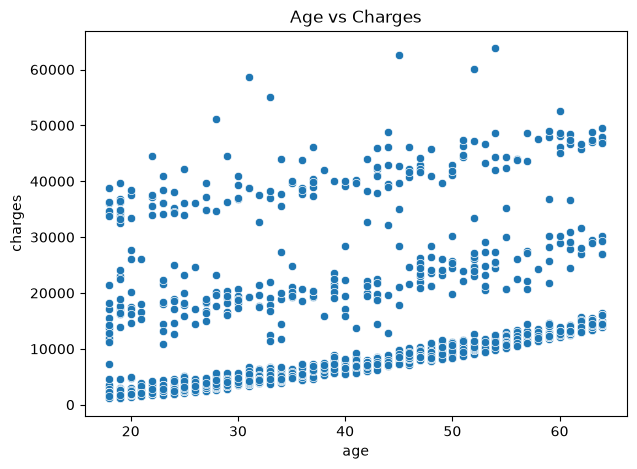

In [44]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="age", y="charges")
plt.title("Age vs Charges")
plt.show()

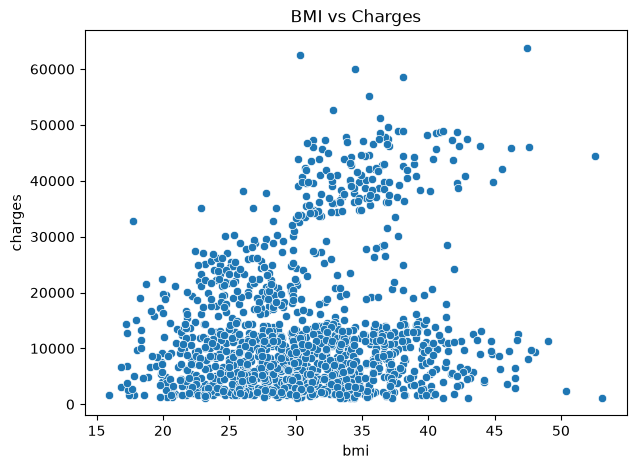

In [45]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="bmi", y="charges")
plt.title("BMI vs Charges")
plt.show()

In [46]:
df.groupby("children")["charges"].agg(["mean", "median", "count"]).round(2)

,mean,median,count
children,,,
0,12384.70,9863.47,573
1,12731.17,8483.87,324
2,15073.56,9264.98,240
3,15355.32,10600.55,157
4,13850.66,11033.66,25
5,8786.04,8589.57,18


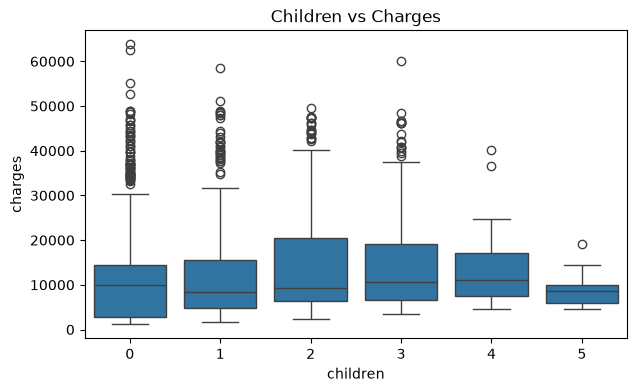

In [47]:
plt.figure(figsize=(7, 4))
sns.boxplot(x="children", y="charges", data=df)
plt.title("Children vs Charges")
plt.show()

### Key Findings
- **Age:** charges increase as age increases (positive relationship), but the points form separate layers, so age alone does not explain charges.
- **BMI:** no clear upward trend. The points form two clouds: a large low-charge cloud and a high-charge cloud mostly at BMI above 30.
- **Children:** weak relationship with charges. The median charges are similar across groups (roughly 8,000-11,000) with no clear upward trend. The groups with 4 and 5 children have very few records, so their results are less reliable.

### Decision
- Keep `age`, `bmi` and `children`.
- The layers in age and the two clouds in BMI suggest another factor (probably `smoker`). This is tested in the interaction section.
- `children` is a weak predictor; its importance will be checked in model building.

----
## 10. Categorical Features vs. Target Analysis

### Objective
Explore how `charges` differ across the categories of each categorical feature.

### Steps
- Group by the category and compare the mean, median and count of `charges`.
- Use boxplots and colored histograms to visualize the difference.

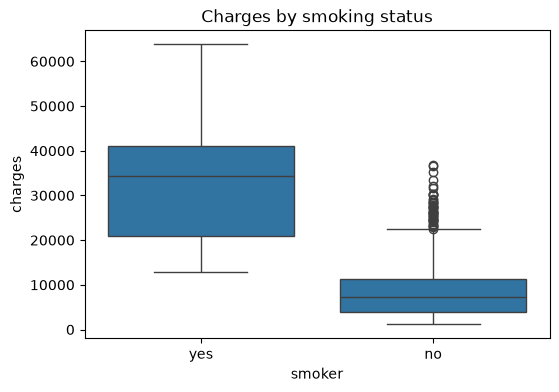

,mean,median,count
smoker,,,
no,8440.660307,7345.72660,1063
yes,32050.231832,34456.34845,274


In [48]:
plt.figure(figsize=(6, 4))
sns.boxplot(x="smoker", y="charges", data=df)
plt.title("Charges by smoking status")
plt.show()

df.groupby("smoker")["charges"].agg(["mean", "median", "count"])

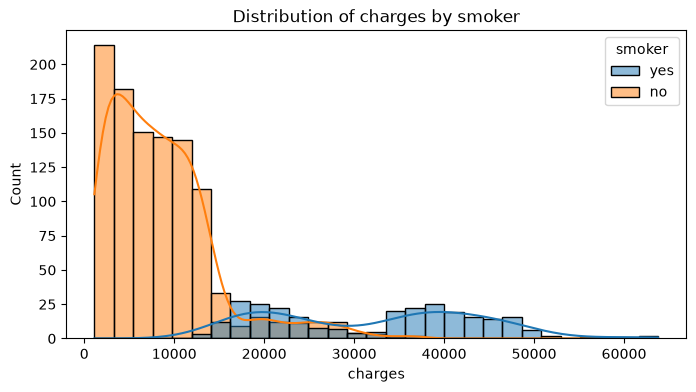

In [49]:
plt.figure(figsize=(8, 4))
sns.histplot(
    data=df,
    x="charges",
    hue="smoker",
    kde=True
)
plt.title("Distribution of charges by smoker")
plt.show()

### Sex and Region: Key Findings
- **Sex:** the median charges are almost identical (9,413 for females vs 9,370 for males). The males' mean is higher (13,957 vs 12,570) because of a few very expensive cases.
- **Region:** the mean charges range from 12,347 (southwest) to 14,735 (southeast) and the median from 8,799 to 10,058. The boxplots overlap heavily.
- Each group has a similar number of records (324 to 364), so the comparison is fair.

### Decision
`sex` and `region` are weak predictors compared to `smoker`. They are kept for now, and their importance will be checked in model building.

----
## 11. Interaction Analysis

### Objective
Check whether the effect of `age` and `bmi` on `charges` changes between smokers and non-smokers.

### Steps
- Scatter plots colored by `smoker`.
- Compare the average charges of obese (BMI >= 30) and non-obese people inside each smoking group.

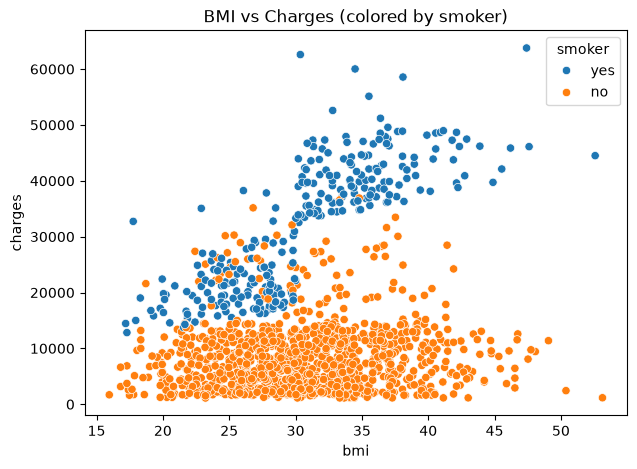

In [50]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker")
plt.title("BMI vs Charges (colored by smoker)")
plt.show()

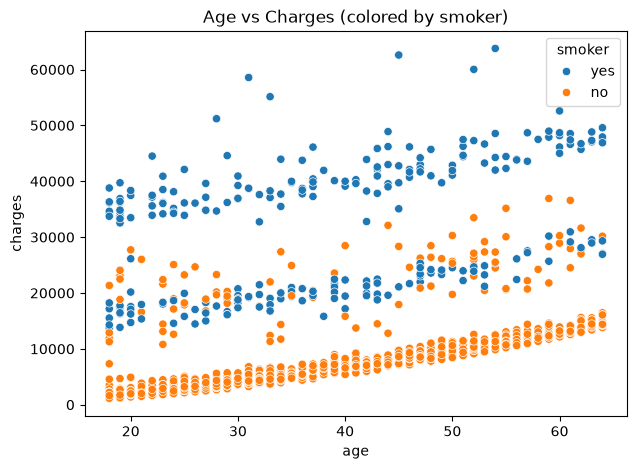

In [51]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker")
plt.title("Age vs Charges (colored by smoker)")
plt.show()

In [52]:
temp = df.assign(obese=df["bmi"] >= 30)
temp.groupby(["smoker", "obese"])["charges"].agg(["mean", "median", "count"]).round(2)

mean    median  count
smoker obese                           
no     False   7977.03   6761.62    502
       True    8855.53   8083.92    561
yes    False  21363.22  20167.34    129
       True   41557.99  40904.20    145

### Key Findings
*(Check each line against your plots and the table above, and fill in the numbers.)*
- The upper cloud in BMI vs charges and the upper layer(s) in age vs charges belong to **smokers**.
- For **non-smokers**, being obese changes the average charges only a little (from __ to __).
- For **smokers**, being obese raises the average charges a lot (from __ to __).
- So the effect of BMI depends on smoking status (an **interaction effect**).

### Decision
Create the features `bmi_obese` (BMI >= 30) and `smoker_obese` (smoker and BMI >= 30) in preprocessing, to help the model capture this interaction.

----
## 12. Correlation Analysis

### Objective
Measure the linear relationship between the numerical features and `charges`.

### Steps
- Correlation matrix and heatmap.
- Correlation of `smoker` (converted temporarily to 0/1) with `charges`.

,age,bmi,children,charges
age,1.00,0.11,0.04,0.30
bmi,0.11,1.00,0.01,0.20
children,0.04,0.01,1.00,0.07
charges,0.30,0.20,0.07,1.00


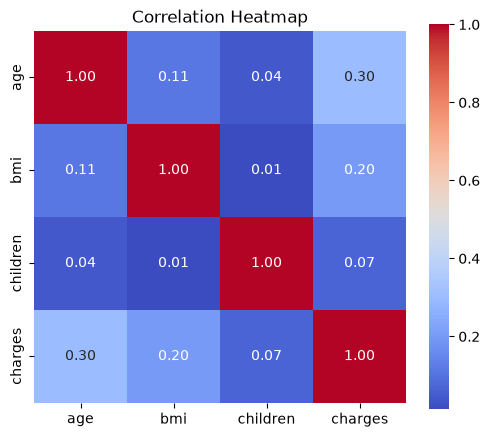

In [53]:
corr = df.corr(numeric_only=True)
display(corr.round(2))

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Heatmap")
plt.show()

In [54]:
temp = df.assign(smoker_num=(df["smoker"] == "yes").astype(int))
temp.corr(numeric_only=True)["charges"].sort_values(ascending=False).round(2)

charges       1.00
smoker_num    0.79
age           0.30
bmi           0.20
children      0.07
Name: charges, dtype: float64

### Key Findings
*(Check the numbers against the outputs above.)*
- Correlation with `charges`: `age` (about 0.30), `bmi` (about 0.20), `children` (about 0.07).
- `smoker` (as 0/1) has the **strongest** correlation with `charges` (about 0.79).
- No strong correlation between the features themselves.

### Decision
No feature is removed based on correlation. Pearson correlation only captures linear relationships, so it does not capture the interaction between `bmi` and `smoker`.

----
## 13. Final Feature Review and EDA Conclusion

### Objective
Finalize the features and summarize the decisions before preprocessing.

In [55]:
X = df.drop(columns=["charges"])
y = df["charges"]

print("Features:", X.columns.tolist())
print("Target:", y.name)
print("X shape:", X.shape, "| y shape:", y.shape)

Features: ['age', 'sex', 'bmi', 'children', 'smoker', 'region']
Target: charges
X shape: (1337, 6) | y shape: (1337,)


In [56]:
numerical_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(exclude="number").columns.tolist()

print("Numerical:", numerical_features)
print("Categorical:", categorical_features)

Numerical: ['age', 'bmi', 'children']
Categorical: ['sex', 'smoker', 'region']


### Feature Types
- **Numerical (3):** `age`, `bmi`, `children`
- **Categorical (3):** `sex`, `smoker`, `region`
- **Target:** `charges`

### EDA Decisions Summary
| What we found in EDA | What we will do in preprocessing |
|---|---|
| 1 duplicated row | Remove it with `clean_data()` |
| No missing values | No imputation needed |
| `charges` is right-skewed | Apply a log transform to `charges` |
| Outliers in `charges` and `bmi` are real cases | Keep them |
| `sex`, `smoker`, `region` are text | Encode them to numbers (one-hot) |
| `smoker` is the strongest predictor | Keep and encode as a feature |
| BMI effect depends on smoking | Add `bmi_obese` and `smoker_obese` |
| `age` has a clear positive effect | Keep (optionally add `age_sq`) |
| `sex`, `region`, `children` are weak | Keep for now, check importance in modeling |